In [1]:
from collections.abc import Mapping
from datetime import datetime
from functools import partial
from pathlib import Path

import torch
from matplotlib.figure import Figure
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2

from mlkit.core.callbacks import Callback, ProgressLogger
from mlkit.core.trainer import Trainer
from mlkit.data.splitter import StratifiedSplitter
from mlkit.data.subsets import TransformSubset
from mlkit.metrics.collections import multiclass_metrics
from mlkit.blocks.conv import ConvBlockConfig
from mlkit.blocks.linear import LinearBlockConfig
from mlkit.models.cnn_classifier import CNNClassifier, CNNConfig
from mlkit.tasks.classification import ClassificationTask
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.visual.confusion import confusion_matrix, plot_confusion_matrix
from mlkit.visual.curves import plot_history
from mlkit.visual.images import plot_image_grid
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

setup_logging()
use_style()

DATASET_PATH = Path("../../datasets/raw/mnist_png")
TRAINING_PATH = DATASET_PATH / "training"
TESTING_PATH = DATASET_PATH / "testing"

SEED = 42
BATCH_SIZE = 100
EPOCHS = 20
LEARNING_RATE = 1e-3
VAL_FRACTION = 0.2
NUM_WORKERS = 2

In [2]:
transform = v2.Compose([
    v2.Grayscale(),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

training_dataset = ImageFolder(TRAINING_PATH)
testing_dataset = ImageFolder(TESTING_PATH, transform=transform)

In [3]:
splitter = StratifiedSplitter((1 - VAL_FRACTION, VAL_FRACTION), seed=SEED)
train_idx, val_idx = splitter.split(training_dataset.targets)
train_ds = TransformSubset(training_dataset, train_idx, transform)
val_ds = TransformSubset(training_dataset, val_idx, transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True,
)
test_loader = DataLoader(testing_dataset, batch_size=BATCH_SIZE, shuffle=False,)

In [4]:
sample, _ = train_ds[0]
channels, height, width = sample.size()

num_classes = len(training_dataset.classes)

cnn_config = CNNConfig(
    in_channels=channels,
    input_size=(height, width),
    conv_configs=(
        ConvBlockConfig(out_channels=24, kernel_size=3, padding=0, pool_size=2),
        ConvBlockConfig(out_channels=36, kernel_size=3, padding=0, pool_size=2),
    ),
    linear_configs=(
        LinearBlockConfig(out_features=128),
        LinearBlockConfig(out_features=num_classes, activation=None),
    ),
)

In [5]:
seed_everything(SEED)

task = ClassificationTask(
    model=CNNClassifier(config=cnn_config),
    optimizer=partial(torch.optim.Adam, lr=LEARNING_RATE),
    metrics=multiclass_metrics(num_classes=num_classes),
)

run_name = f"lab1_part1_{datetime.now():%Y%m%d_%H%M%S}"
writer = SummaryWriter(log_dir=f"runs/{run_name}")
saver = FigureSaver(Path("artifacts") / run_name)


def save_figure(fig: Figure, name: str) -> None:
    saver.save(fig, name)
    writer.add_figure(name, fig, close=False)


class TensorBoardScalars(Callback):
    def __init__(self, writer: SummaryWriter) -> None:
        self.writer = writer

    def on_epoch_end(self, trainer: Trainer, epoch: int, logs: Mapping[str, float]) -> None:
        for key, value in logs.items():
            split, _, name = key.partition("/")
            self.writer.add_scalars(name, {split: value}, epoch)


hparams: dict[str, int | float | str] = {
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "optimizer": type(task.opt).__name__,
    "learning_rate": LEARNING_RATE,
}
writer.add_text("hparams", "\n".join(f"- {name}: {value}" for name, value in hparams.items()))

trainer = Trainer(callbacks=[ProgressLogger(metrics=["loss", "accuracy"]), TensorBoardScalars(writer)])
history = trainer.fit(task, train_loader, val_loader, epochs=EPOCHS)

Epoch 1 | train/loss 0.3189 train/accuracy 0.905 val/loss 0.1119 val/accuracy 0.9658 | 177.5s
Epoch 2 | train/loss 0.08038 train/accuracy 0.9751 val/loss 0.06663 val/accuracy 0.98 | 103.5s
Epoch 3 | train/loss 0.05608 train/accuracy 0.9826 val/loss 0.05274 val/accuracy 0.9828 | 12.6s
Epoch 4 | train/loss 0.04339 train/accuracy 0.9863 val/loss 0.05141 val/accuracy 0.9832 | 12.7s
Epoch 5 | train/loss 0.03533 train/accuracy 0.9895 val/loss 0.04675 val/accuracy 0.9852 | 12.9s
Epoch 6 | train/loss 0.02853 train/accuracy 0.9911 val/loss 0.04219 val/accuracy 0.9868 | 13.3s
Epoch 7 | train/loss 0.0233 train/accuracy 0.9931 val/loss 0.03997 val/accuracy 0.9875 | 12.8s
Epoch 8 | train/loss 0.01886 train/accuracy 0.9941 val/loss 0.03783 val/accuracy 0.9886 | 12.3s
Epoch 9 | train/loss 0.01558 train/accuracy 0.995 val/loss 0.03859 val/accuracy 0.988 | 12.3s
Epoch 10 | train/loss 0.0137 train/accuracy 0.9958 val/loss 0.03815 val/accuracy 0.9891 | 12.5s
Epoch 11 | train/loss 0.01167 train/accuracy 0

Best val loss 0.0378 at epoch 8
Best val accuracy 0.9907 at epoch 15


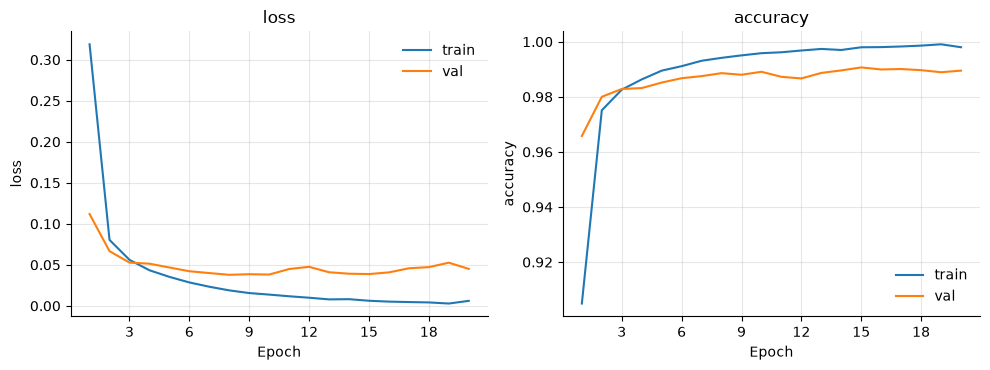

In [6]:
save_figure(plot_history(history, ["loss", "accuracy"]), "training_curves")

best_epoch, best_loss = history.best("val/loss", mode="min")
best_acc_epoch, best_acc = history.best("val/accuracy", mode="max")
print(f"Best val loss {best_loss:.4f} at epoch {best_epoch}")
print(f"Best val accuracy {best_acc:.4f} at epoch {best_acc_epoch}")

In [7]:
test_results = trainer.evaluate(task, test_loader)
probs, targets = task.predict(test_loader)
preds = probs.argmax(dim=1)
print(test_results)

{'loss': 0.04164075175831641, 'accuracy': 0.9902999997138977, 'f1': 0.9902045726776123, 'precision': 0.9903044700622559, 'recall': 0.9901365041732788}


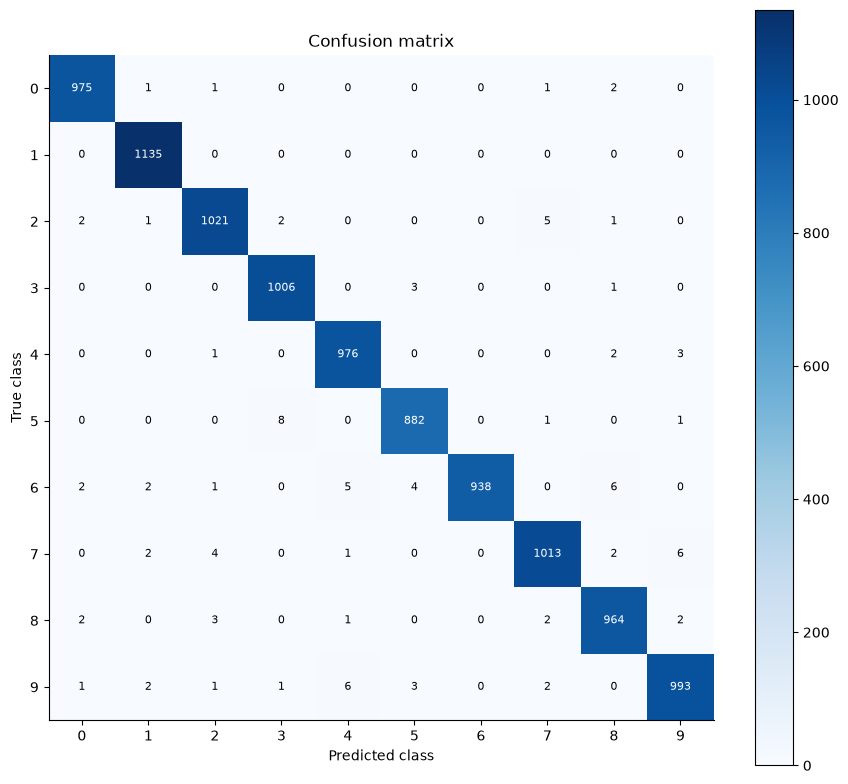

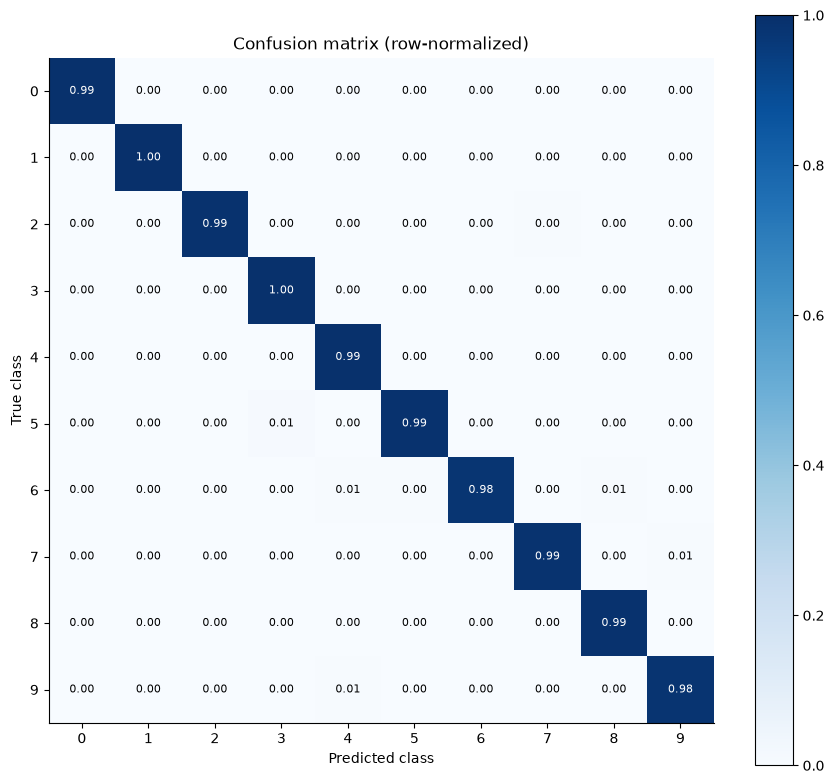

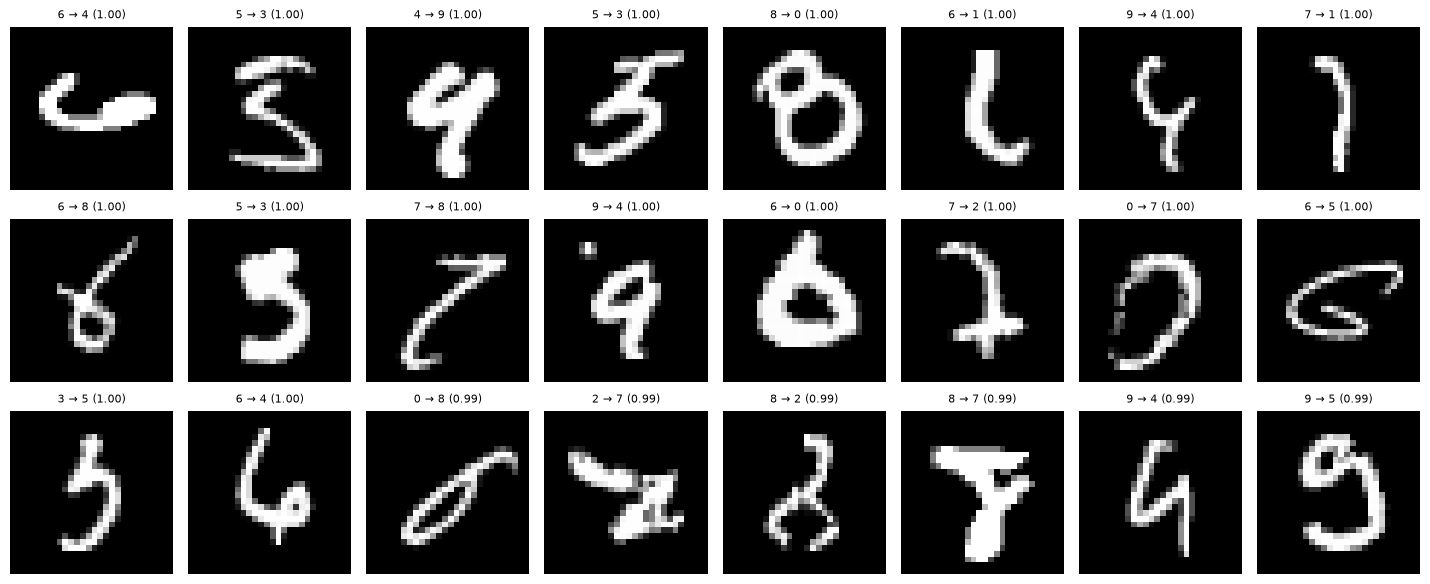

In [8]:
class_names: list[str] = testing_dataset.classes
matrix = confusion_matrix(preds, targets, num_classes=len(class_names))

save_figure(plot_confusion_matrix(matrix, class_names), "confusion_counts")
save_figure(plot_confusion_matrix(matrix, class_names, normalize=True), "confusion_normalized")

wrong = (preds != targets).nonzero().flatten()
confidence = probs[wrong, preds[wrong]]
errors = wrong[confidence.argsort(descending=True)][:24].tolist()
error_images = torch.stack([testing_dataset[i][0] for i in errors])
error_titles = [
    f"{class_names[targets[i]]} → {class_names[preds[i]]} ({probs[i, preds[i]]:.2f})"
    for i in errors
]
save_figure(plot_image_grid(error_images, error_titles), "misclassified")

In [9]:
writer.add_hparams(
    hparams,
    {f"test/{name}": value for name, value in test_results.items()},
    run_name="hparams",
)
writer.close()

In [10]:
import os
import shutil
import subprocess
import sys
import tempfile

os.environ["TENSORBOARD_BINARY"] = str(Path(sys.executable).parent / "tensorboard.exe")
subprocess.run(["taskkill", "/IM", "tensorboard.exe", "/T", "/F"], capture_output=True)
shutil.rmtree(Path(tempfile.gettempdir()) / ".tensorboard-info", ignore_errors=True)

%reload_ext tensorboard
%tensorboard --logdir runs